# Dataset overview
What the two datasets contain. This notebook only reads the data, it never changes it.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

MRI = Path("../data/MRI dataset")
BTXRD = Path("../data/BTXRD dataset")

MALIGNANT = {"osteosarcoma", "other mt"}  # all other tumor types are benign


def show_images(paths, title):
    fig, axes = plt.subplots(1, len(paths), figsize=(3 * len(paths), 3))
    for ax, path in zip(axes, paths):
        ax.imshow(Image.open(path), cmap="gray")
        ax.set_title(path.name, fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

## MRI dataset

In [2]:
mri_rows = []
for folder in ["Cancer", "Normal"]:
    for path in sorted((MRI / folder).glob("*.jpg")):
        mri_rows.append({"file": path, "class": folder, "size": Image.open(path).size})
mri = pd.DataFrame(mri_rows)

print("Images per class:")
print(mri["class"].value_counts().to_string())
print("\nImage sizes per class:")
print(mri.groupby("class")["size"].value_counts().to_string())

Images per class:
class
Cancer    25
Normal    25

Image sizes per class:
class   size      
Cancer  (224, 224)    25
Normal  (227, 227)    24
        (225, 225)     1


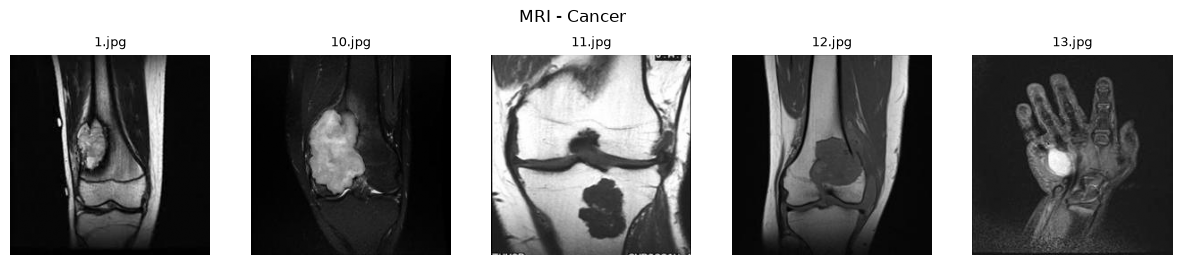

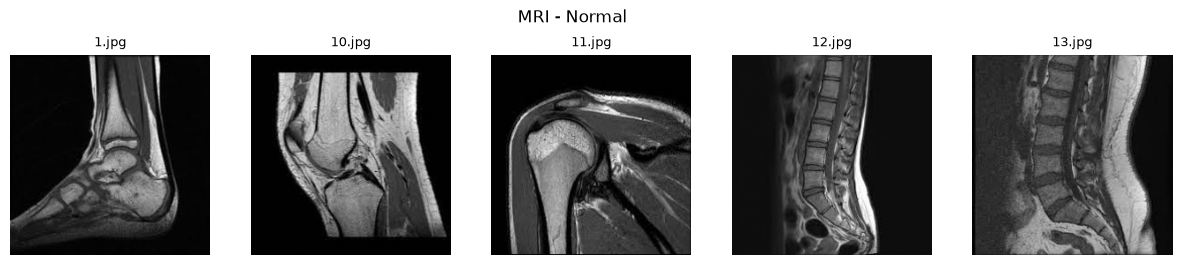

In [3]:
for folder in ["Cancer", "Normal"]:
    show_images(list(mri[mri["class"] == folder]["file"][:5]), f"MRI - {folder}")

## BTXRD dataset
An image **with** an annotation file is a tumor image. An image **without** one is normal.

In [4]:
btxrd_rows = []
for path in sorted(BTXRD.glob("images/*.jp*g")):  # .jpg and .jpeg
    annotation = BTXRD / "Annotations" / (path.stem + ".json")
    if annotation.exists():
        tumor_type = json.loads(annotation.read_text())["shapes"][0]["label"]
        group = "malignant" if tumor_type in MALIGNANT else "benign"
    else:
        tumor_type, group = "-", "normal"
    btxrd_rows.append({"file": path, "name": path.stem, "group": group,
                       "tumor type": tumor_type, "size": Image.open(path).size})
btxrd = pd.DataFrame(btxrd_rows)

print("Images:", len(btxrd))
print("Annotation files:", len(list(BTXRD.glob("Annotations/*.json"))))
print("\nImages per group:")
print(btxrd["group"].value_counts().to_string())

Images: 3746
Annotation files: 1867

Images per group:
group
normal       1879
benign       1525
malignant     342


### Tumor types

In [5]:
print(btxrd[btxrd["group"] != "normal"].groupby("group")["tumor type"].value_counts().to_string())

group      tumor type              
benign     osteochondroma              753
           multiple osteochondromas    263
           simple bone cyst            206
           other bt                    115
           giant cell tumor             93
           synovial osteochondroma      51
           osteofibroma                 44
malignant  osteosarcoma                297
           other mt                     45


### Image sizes


In [6]:
print(btxrd["size"].value_counts().to_string())

size
(2440, 2440)    3746


### Duplicates
Images that are exact copies of another image. Pairs are shown next to each other.

In [7]:
btxrd["hash"] = [hashlib.md5(path.read_bytes()).hexdigest() for path in btxrd["file"]]
duplicates = btxrd[btxrd.duplicated("hash", keep=False)].sort_values("hash")

print("Duplicate pairs:", duplicates["hash"].nunique())
print("Pairs with different labels:", (duplicates.groupby("hash")["group"].nunique() > 1).sum())
duplicates[["name", "group", "tumor type"]]

Duplicate pairs: 21
Pairs with different labels: 2


,name,group,tumor type
3684,IMG003685,normal,-
3668,IMG003669,normal,-
2167,IMG002168,normal,-
1951,IMG001952,normal,-
1765,IMG001766,benign,osteochondroma
1732,IMG001733,benign,osteochondroma
1872,IMG001873,normal,-
3323,IMG003324,normal,-
1798,IMG001799,benign,osteochondroma
1720,IMG001721,benign,osteochondroma


### Examples

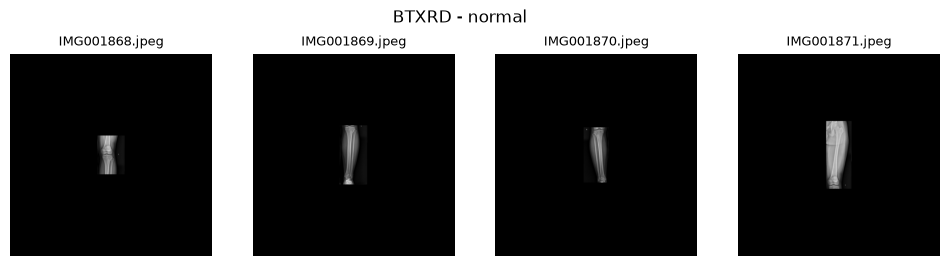

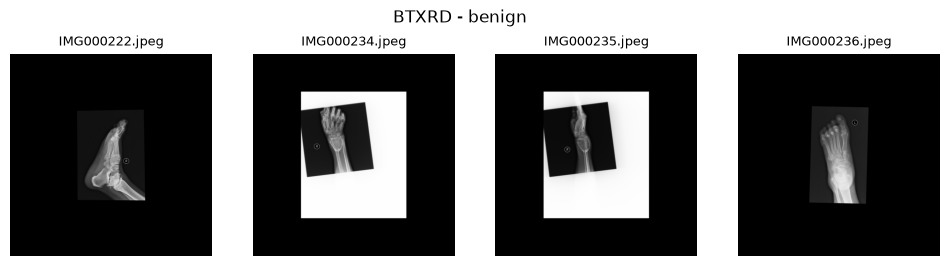

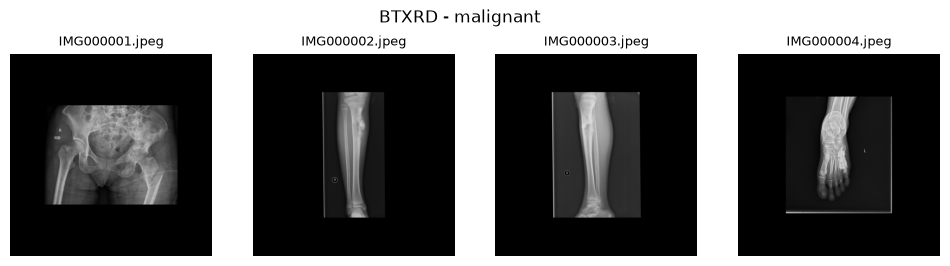

In [8]:
for group in ["normal", "benign", "malignant"]:
    show_images(list(btxrd[btxrd["group"] == group]["file"][:4]), f"BTXRD - {group}")